<div align="center">
    <span style="font-size:30px">
        <strong>
            <!-- Símbolo de Python -->
            <img
                src="https://cdn3.emoji.gg/emojis/1887_python.png"
                style="margin-bottom:-5px"
                width="30px" 
                height="30px"
            >
            <!-- Título -->
            Python para Geólogos
            <!-- Versión -->
            <img 
                src="https://img.shields.io/github/release/kevinalexandr19/manual-python-geologia.svg?style=flat&label=&color=blue"
                style="margin-bottom:-2px" 
                width="40px"
            >
        </strong>
    </span>
    <br>
    <span>
        <!-- Github del proyecto -->
        <a href="https://github.com/kevinalexandr19/manual-python-geologia" target="_blank">
            <img src="https://img.shields.io/github/stars/kevinalexandr19/manual-python-geologia.svg?style=social&label=Github Repo">
        </a>
        &nbsp;&nbsp;
        <!-- Licencia -->
        <img src="https://img.shields.io/github/license/kevinalexandr19/manual-python-geologia.svg?color=forestgreen">
        &nbsp;&nbsp;
        <!-- Release date -->
        <img src="https://img.shields.io/github/release-date/kevinalexandr19/manual-python-geologia?color=gold">
    </span>
    <br>
    <span>
        <!-- Perfil de LinkedIn -->
        <a target="_blank" href="https://www.linkedin.com/in/kevin-alexander-gomez/">
            <img src="https://img.shields.io/badge/-Kevin Alexander Gomez-5eba00?style=social&logo=linkedin">
        </a>
        &nbsp;&nbsp;
        <!-- Perfil de Github -->
        <a target="_blank" href="https://github.com/kevinalexandr19">
            <img src="https://img.shields.io/github/followers/kevinalexandr19.svg?style=social&label=kevinalexandr19&maxAge=2592000">
        </a>
    </span>
    <br>
</div>

***

<span style="color:lightgreen; font-size:25px">**PG301 - Geoestadística** </span>

Bienvenido al curso!!!

Vamos a revisar las bases de la <span style="color:gold">geoestadística</span> usando ejemplos en Python. <br>
Es necesario que tengas un conocimiento previo en programación con Python, estadística y geología general.

<span style="color:gold; font-size:20px">**Declustering** </span>

***
- [Representatividad en el muestreo](#parte-1)
- [¿Qué es declustering?](#parte-2)
- [Declustering con Python](#parte-3)
- [Interpretación](#parte-4)

***

In [ ]:
import sys

if sys.platform == "emscripten":
    import piplite
    await piplite.install(['numpy', 'pandas', 'matplotlib'])

<a id="parte-1"></a>

### <span style="color:lightgreen">**Representatividad en el muestreo geoestadístico**</span>
***

Una muestra es representativa en relación con una **población de interés**. En un área con muestreo preferencial puede haber muchas observaciones en una zona pequeña. El promedio simple describe las muestras, pero esa zona contribuye más que otras al resultado.

Un diseño aleatorio o sistemático ayuda a cubrir el dominio. Con datos ya recolectados, el desagrupamiento cambia la contribución de las muestras en zonas densas. Conviene revisar accesos, campañas, contactos y sectores sin datos antes de interpretar una media ponderada.

<a id="parte-2"></a>

### <span style="color:lightgreen">**¿Qué es declustering?**</span>
***

El <span style="color:gold">desagrupamiento por celdas</span> divide el plano en una malla. Para un origen y un tamaño fijos, repartimos el mismo peso total a cada celda **ocupada**. Sus muestras se reparten ese peso. Una celda con tres muestras da menos peso a cada muestra que una celda con una sola.

Si hay $M$ celdas ocupadas y $n_j$ muestras en la celda $j$, asignamos $1/(M n_j)$ a cada muestra de esa celda. Aquí los pesos suman 1. Si multiplicamos todos los pesos por el número de muestras obtenemos pesos relativos con media 1. Las dos escalas dan la misma media ponderada.

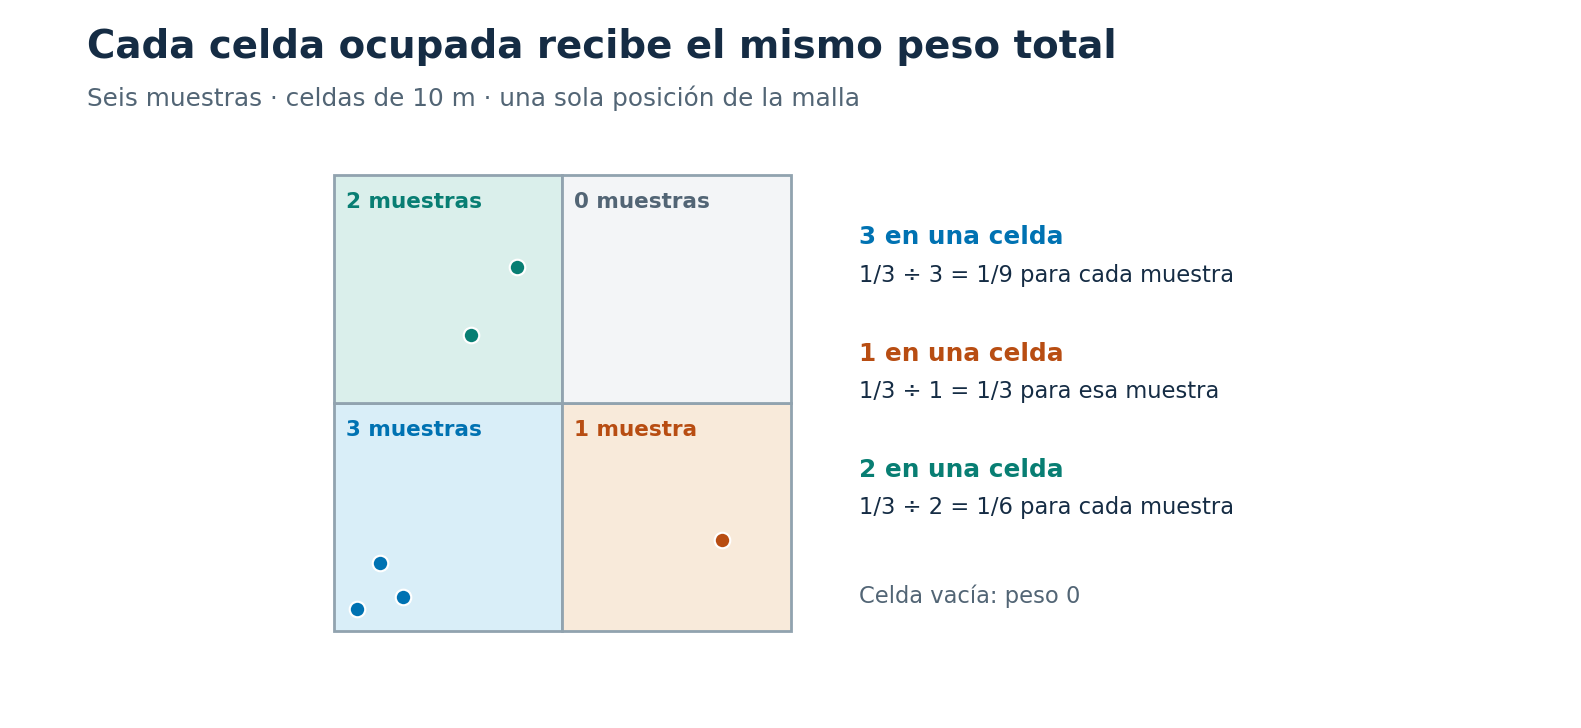

Anticipa el peso de una muestra en la celda azul y de la muestra naranja. Cambiar el origen puede mover alguna muestra de celda.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def pesos_celdas(xy, lado, origen):
    # Convertir cada coordenada a un índice de fila y columna de la malla.
    celdas = np.floor((xy - origen) / lado).astype(int)
    # Cada id identifica una celda ocupada y conteos[id] da su ocupación.
    _, id_celda, conteos = np.unique(celdas, axis=0, return_inverse=True, return_counts=True)
    return 1.0 / (len(conteos) * conteos[id_celda])

xy_ejemplo = np.array([[1, 1], [3, 1.5], [2, 3], [17, 4], [6, 13], [8, 16]])
phi_ejemplo = np.array([18, 19, 20, 8, 10, 12])
w_ejemplo = pesos_celdas(xy_ejemplo, lado=10, origen=np.array([0, 0]))
print(f"Suma de pesos: {w_ejemplo.sum():.3f}")
print(f"Media simple: {phi_ejemplo.mean():.2f}% | media ponderada: {np.average(phi_ejemplo, weights=w_ejemplo):.2f}%")
pd.DataFrame({"Este": xy_ejemplo[:, 0], "Norte": xy_ejemplo[:, 1],
              "Porosidad (%)": phi_ejemplo, "Peso": w_ejemplo}).round(3)

El mismo algoritmo se conoce como *cell declustering* en GSLIB. Vamos a mantener a la vista las operaciones de conteo y media para poder verificar el cálculo en el navegador.

[Deutsch, Cell Declustering Parameter Selection](https://geostatisticslessons.com/lessons/celldeclustering)

<a id="parte-3"></a>

### <span style="color:lightgreen">**Declustering con Python**</span>
***

Retomamos `data_sesgada.csv`. `X` y `Y` están en metros. La facies 1 corresponde a arenisca y la 0 a intercalaciones de arenisca y lutita. Convertimos **porosidad en fracción** a porcentaje y conservamos permeabilidad en mD.

Para esta práctica suponemos que la toma de muestras favoreció sectores de alta porosidad. Esa hipótesis motiva buscar un tamaño que reduzca la media. En un estudio real, el mapa ayuda a formular la hipótesis y los registros de campaña ayudan a comprobarla.

In [ ]:
data = pd.read_csv("files/data_sesgada.csv")
validas = np.isfinite(data[["X", "Y", "Porosidad"]]).all(axis=1)
data = data.loc[validas].copy()
data["Porosidad_pct"] = 100 * data["Porosidad"]
xy = data[["X", "Y"]].to_numpy()
phi = data["Porosidad_pct"].to_numpy()
base = xy.min(axis=0)
media_simple = phi.mean()
print(f"Muestras utilizables: {len(data)} | Porosidad media simple: {media_simple:.2f}%")
data.head().round(3)

Si cambiamos el origen, algunas muestras pasan a otras celdas. Para cada tamaño desplazaremos la malla por fracciones de su lado en ambas direcciones. Usaremos 16 orígenes fijos para poder reproducir el cálculo. Promediamos los pesos de cada muestra entre orígenes. También guardamos las medias de cada origen para ver la sensibilidad.

In [ ]:
fracciones = np.array([(x, y) for x in [0, .25, .5, .75] for y in [0, .25, .5, .75]])
tamanos = np.unique(np.r_[np.arange(10, 401, 10), np.arange(450, 2001, 50)])

def revisar_tamano(lado):
    pesos = np.array([pesos_celdas(xy, lado, base + lado * f) for f in fracciones])
    pesos_medios = pesos.mean(axis=0)
    medias_origen = pesos @ phi
    return pesos_medios, medias_origen

pruebas = [revisar_tamano(lado) for lado in tamanos]
medias = np.array([m for _, m in pruebas])
dmeans = medias.mean(axis=1)
indice = dmeans.argmin()
lado_elegido = tamanos[indice]
wts = pruebas[indice][0]
data["Peso_relativo"] = len(data) * wts
print(f"Tamaño seleccionado con este criterio: {lado_elegido:g} m")
print(f"Media ponderada: {np.average(phi, weights=wts):.2f}%")

La línea es la media de los orígenes y la banda va del mínimo al máximo entre ellos. La banda mide sensibilidad al origen. Con celdas pequeñas, muchas muestras quedan solas y los pesos pueden acercarse entre sí. Con una sola celda ocupada, volvemos exactamente a pesos iguales.

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4.1))
ax.fill_between(tamanos, medias.min(axis=1), medias.max(axis=1), color="#0072B2",
                alpha=.16, label="Mínimo–máximo entre orígenes")
ax.plot(tamanos, dmeans, "o-", color="#0072B2", markersize=3, label="Media entre orígenes")
ax.axhline(media_simple, color="0.45", ls="--", label=f"Media simple · {media_simple:.2f}%")
ax.scatter(lado_elegido, dmeans[indice], s=69, color="#B84D12",
           label=f"Mínimo probado · {lado_elegido:g} m", zorder=4)
ax.set(title="Sensibilidad al tamaño y al origen de la malla", xlabel="Lado de celda (m)",
       ylabel="Porosidad media (%)")
ax.grid(alpha=.19)
ax.legend(frameon=False, fontsize=9)
fig.tight_layout()
plt.show()

Ubica las muestras que pierden o ganan influencia. En el segundo mapa, peso relativo 1 representa la contribución que tenía cada fila en la media simple. La contribución cambia por la geometría de muestreo y por la escala elegida.

In [ ]:
fig, ejes = plt.subplots(1, 2, figsize=(10, 4.6), sharex=True, sharey=True)
for ax, campo, color, titulo in zip(
    ejes, ["Porosidad_pct", "Peso_relativo"], ["viridis", "cividis"],
    ["Porosidad medida (%)", f"Peso relativo con celdas de {lado_elegido:g} m"]
):
    puntos = ax.scatter(*xy.T, c=data[campo], cmap=color, s=28, edgecolors="0.25", linewidths=.25)
    ax.set(title=titulo, xlabel="Este (m)", aspect="equal")
    fig.colorbar(puntos, ax=ax, shrink=.78)
ejes[0].set_ylabel("Norte (m)")
fig.tight_layout()
plt.show()

<a id="parte-4"></a>

### <span style="color:lightgreen">**Interpretación**</span>
***

Para comparar distribuciones, ordenamos las mismas muestras de menor a mayor porosidad. La curva acumulada ponderada suma los pesos en ese orden. Una muestra con mayor peso produce un salto mayor. Calculamos media y desviación ponderada a partir de las mismas filas.

In [ ]:
orden = np.argsort(phi)
phi_ordenada = phi[orden]
cdf_simple = np.arange(1, len(phi) + 1) / len(phi)
cdf_ponderada = np.cumsum(wts[orden]) / wts.sum()
media_ponderada = np.average(phi, weights=wts)
sd_ponderada = np.sqrt(np.average((phi - media_ponderada)**2, weights=wts))
print(f"Media simple: {media_simple:.2f}% | ponderada: {media_ponderada:.2f}%")
print(f"Desviación simple: {phi.std():.2f} | ponderada: {sd_ponderada:.2f} puntos porcentuales")
fig, ax = plt.subplots(figsize=(8, 3.9))
ax.step(phi_ordenada, cdf_simple, where="post", color="#526575", label="Pesos iguales")
ax.step(phi_ordenada, cdf_ponderada, where="post", color="#0072B2", label="Pesos por celda")
ax.set(xlabel="Porosidad (%)", ylabel="Proporción acumulada", ylim=(0, 1.03),
       title="La distribución cambia al ponderar las mismas muestras")
ax.legend(frameon=False)
ax.grid(alpha=.2)
fig.tight_layout()
plt.show()

**Comprueba tu lectura.** Mueve el origen de la malla de seis muestras y predice qué pesos cambian. En los datos de porosidad, compara dos tamaños vecinos al mínimo y revisa si la diferencia es grande respecto a la banda. Si un sector quedó sin muestrear, ¿qué evidencia adicional necesitarías para describirlo?

El desagrupamiento cambia la influencia de los datos observados. La elección del tamaño depende del espaciamiento, el dominio y el tipo de muestreo. Podemos reportar la media simple junto con la ponderada, el tamaño usado y una medida de sensibilidad al origen.